# Example of the `aitlas` toolbox in the context of multi class image classification

This notebook shows a sample implementation of a multi class image classification using the `aitlas` toolbox and the PatternNet dataset.

In [ ]:
from aitlas.datasets import PatternNetDataset
from aitlas.models import ResNet50
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [9]:
dataset_config = {
    "data_dir": "/home/dragik/data/PatternNet/", 
    "csv_file": "/home/dragik/data/PatternNet/train.csv"
    }
dataset = PatternNetDataset(dataset_config)

## Show images from the dataset

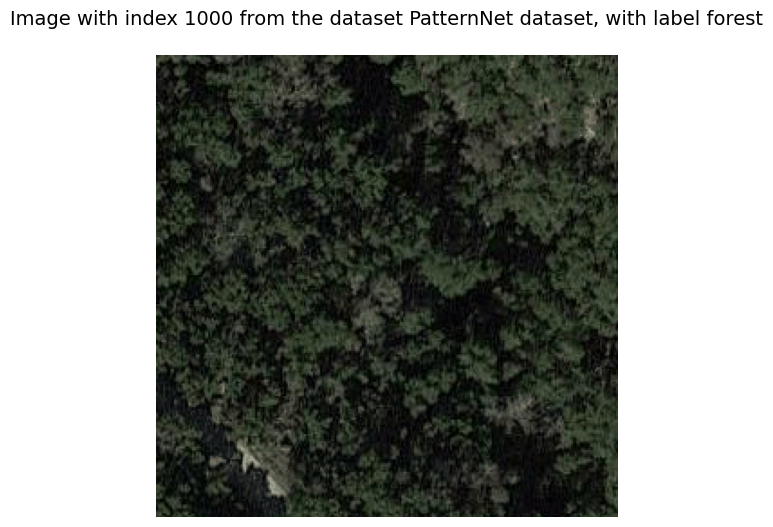

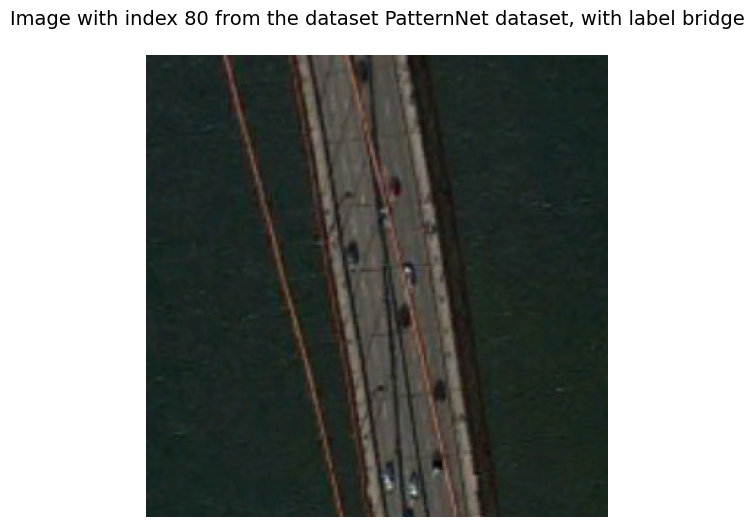

In [10]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(80)

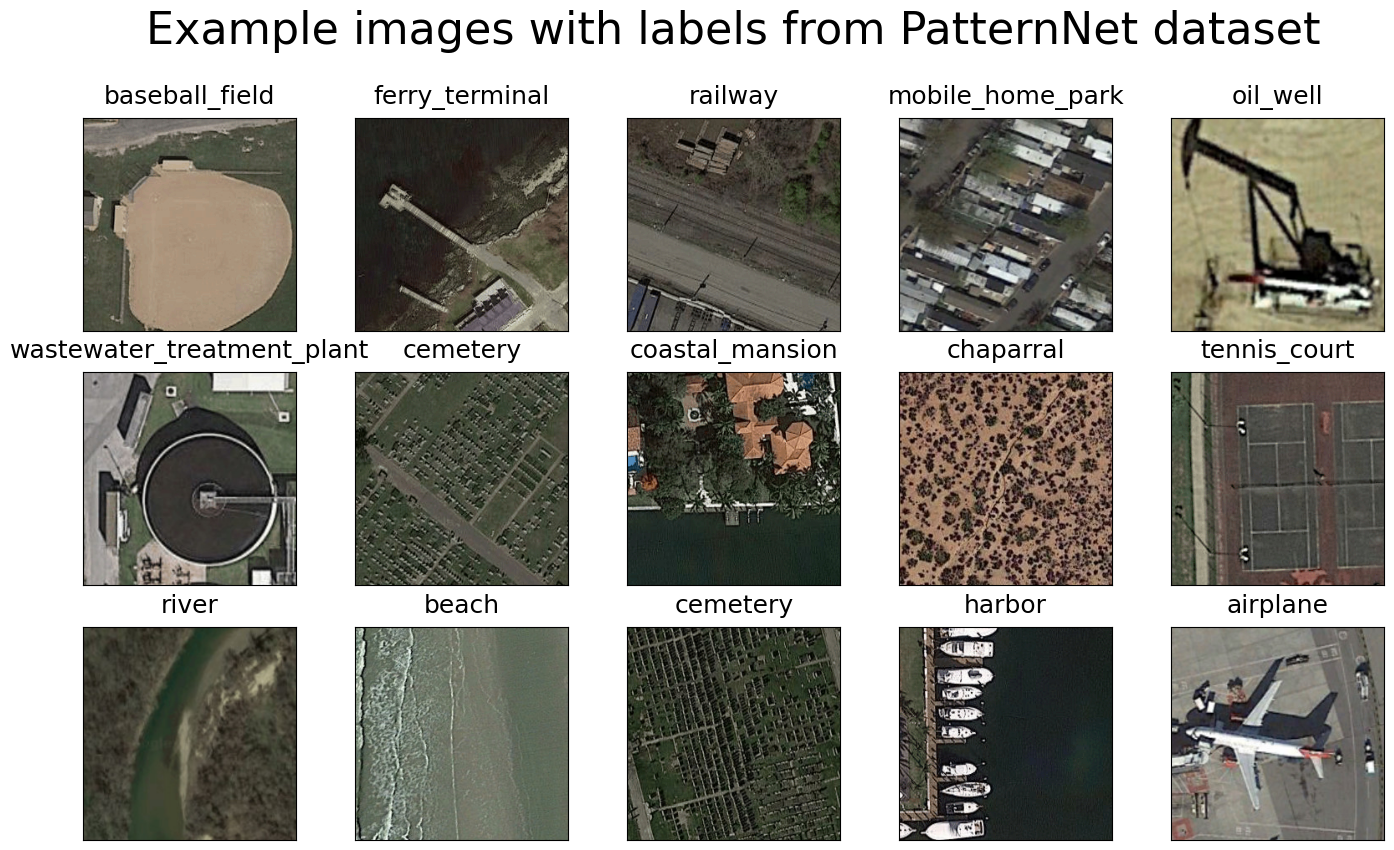

In [12]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [14]:
dataset.data_distribution_table()

,Label,Count
0,airplane,720
1,baseball_field,720
2,basketball_court,720
3,beach,720
4,bridge,720
5,cemetery,720
6,chaparral,720
7,christmas_tree_farm,720
8,closed_road,720
9,coastal_mansion,720


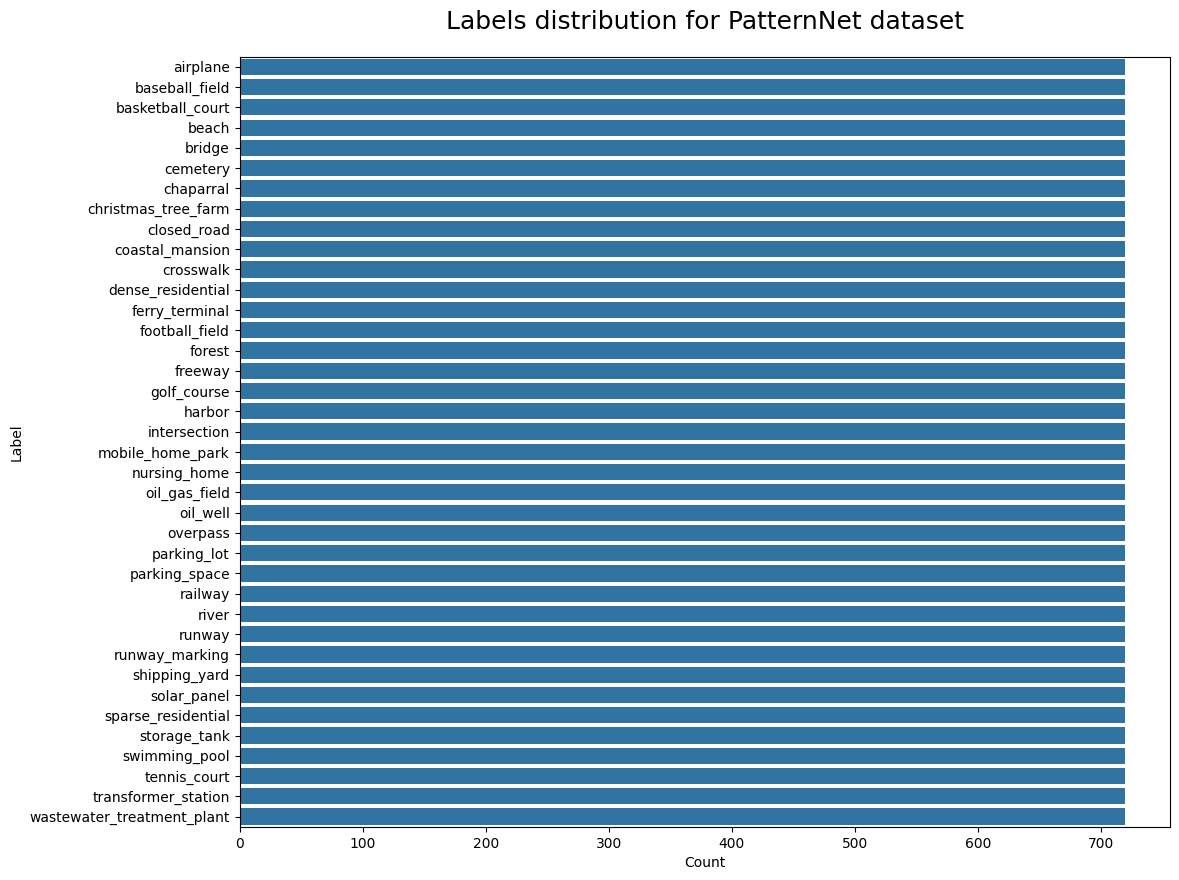

In [15]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [16]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/PatternNet",
    "csv_file": "/home/dragik/data/PatternNet/train.csv",
}

train_dataset = PatternNetDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/PatternNet",
    "csv_file": "/home/dragik/data/PatternNet/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = PatternNetDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(27360, 6080)

## Setup and create the model for training

In [17]:
epochs = 10
model_directory = "/home/dragik/data/experiments/PatternNet"
model_config = {
    "num_classes": 38,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50(model_config)
model.prepare()

## Training and evaluation

In [18]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 09:04:43,096 INFO Starting training.
training: 100%|██████████| 1710/1710 [02:06<00:00, 13.52it/s]
2026-08-24 09:06:49,866 INFO epoch: 1, time: 126, loss:  0.45971
testing on train set: 100%|██████████| 1710/1710 [01:00<00:00, 28.30it/s]
2026-08-24 09:07:51,069 INFO Accuracy:0.9913377192982457, Precision Micro:0.9913377192982457, Precision Macro:0.9914998649183422, Precision Weighted:0.9914998649183422, Precision per Class:[0.99584488 0.99173554 0.99858557 1.         0.99709302 0.98630137
 1.         1.         0.99584488 0.95983936 0.99861304 0.98628258
 0.99401198 0.99860918 1.         0.99722992 1.         0.9729364
 0.96761134 0.99173554 0.99423631 1.         1.         0.97956403
 1.         0.99173554 0.99722222 1.         0.99722607 0.99861111
 0.97693351 1.         0.98988439 0.98901099 0.99722222 0.99441341
 0.99568966 0.94297082], Recall Micro:0.9913377192982457, Recall Macro:0.9913377192982454, Recall Weighted:0.9913377192982455, Recall per Class:[0.99861111 1.   

0.028576705927427174

## Predictions

2026-08-24 09:39:56,124 INFO Loading checkpoint /home/dragik/data/experiments/PatternNet/checkpoint.pth.tar
2026-08-24 09:39:56,519 INFO Loaded checkpoint /home/dragik/data/experiments/PatternNet/checkpoint.pth.tar at epoch 11


3040


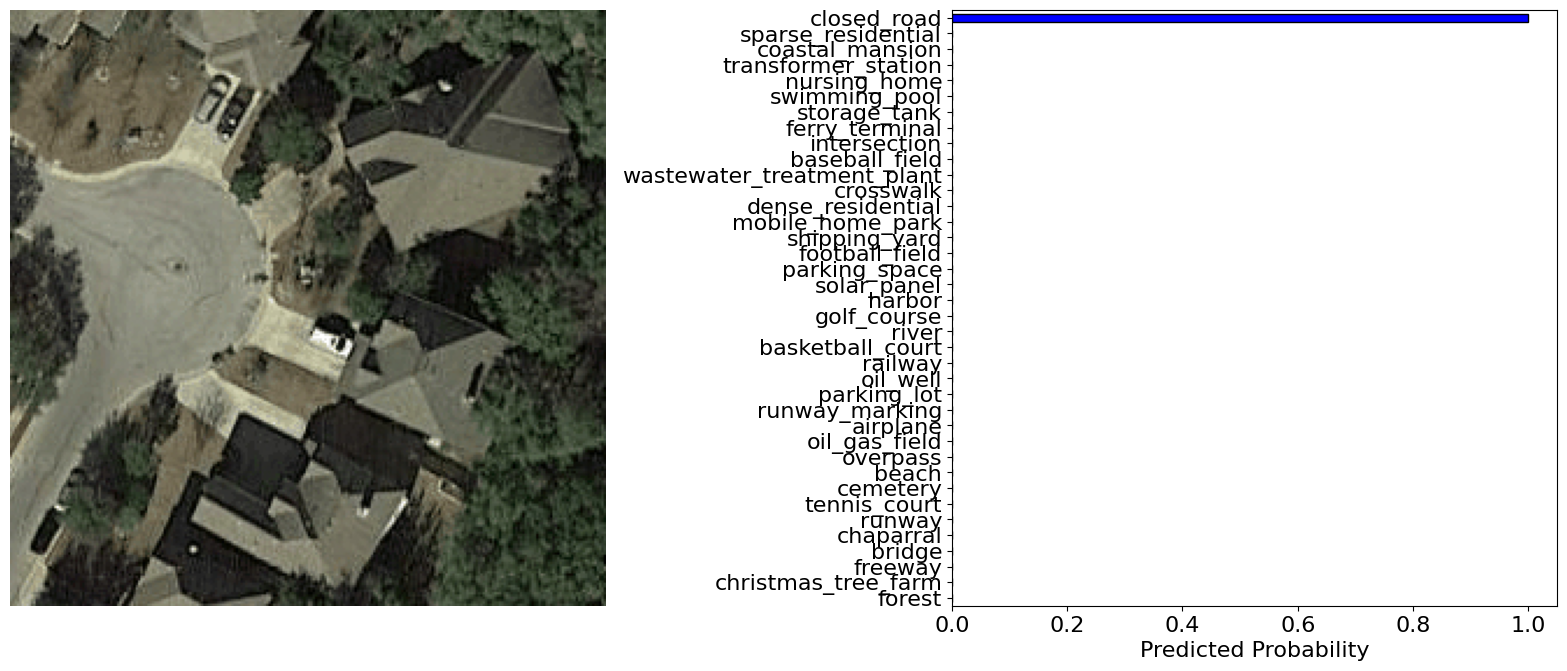

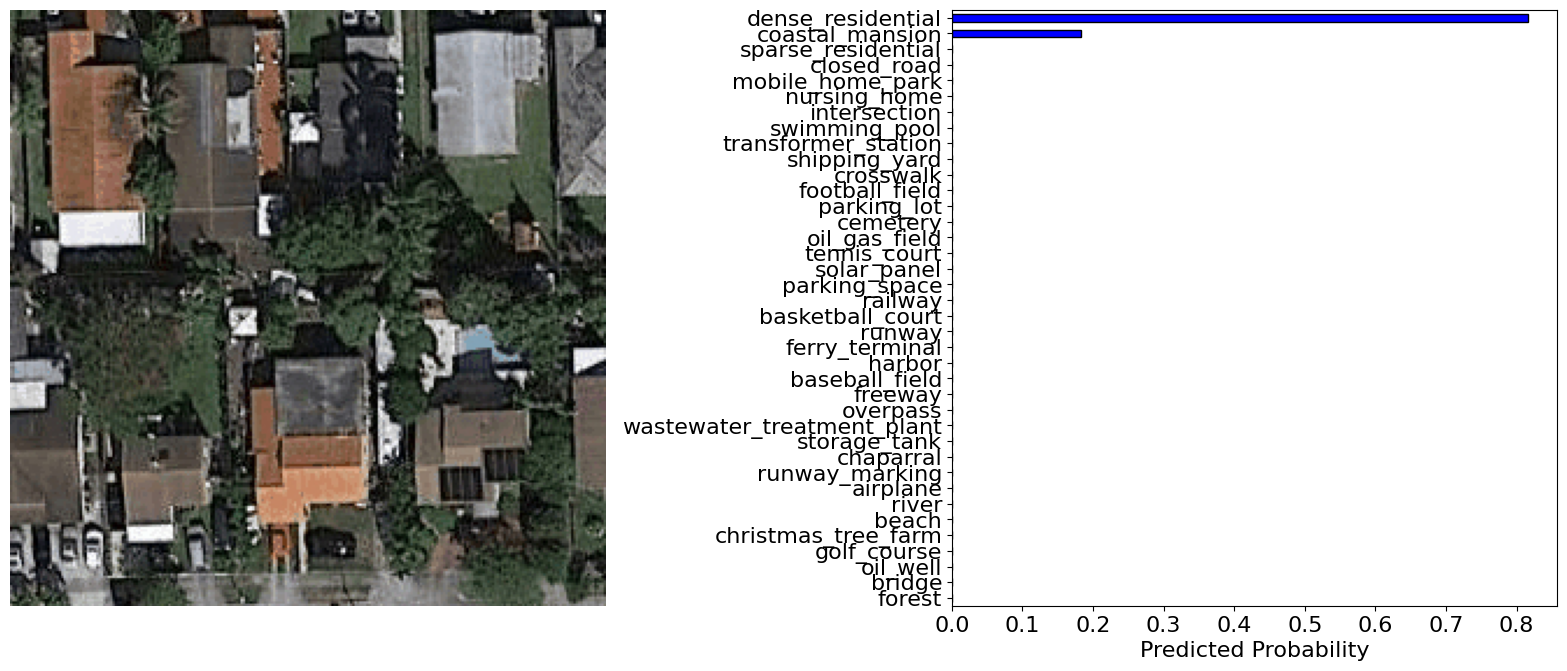

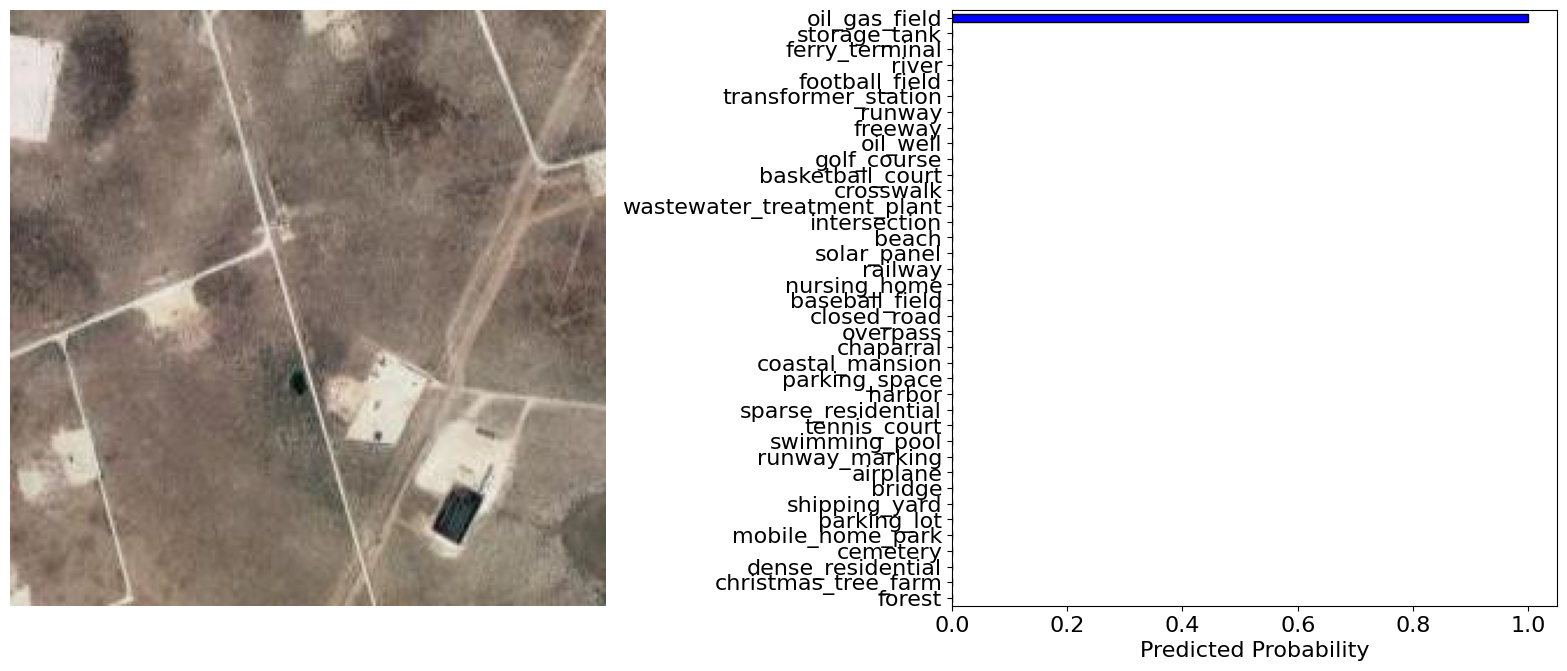

In [19]:
model_path = "/home/dragik/data/experiments/PatternNet/checkpoint.pth.tar"
labels = [
    "airplane",
    "baseball_field",
    "basketball_court",
    "beach",
    "bridge",
    "cemetery",
    "chaparral",
    "christmas_tree_farm",
    "closed_road",
    "coastal_mansion",
    "crosswalk",
    "dense_residential",
    "ferry_terminal",
    "football_field",
    "forest",
    "freeway",
    "golf_course",
    "harbor",
    "intersection",
    "mobile_home_park",
    "nursing_home",
    "oil_gas_field",
    "oil_well",
    "overpass",
    "parking_lot",
    "parking_space",
    "railway",
    "river",
    "runway",
    "runway_marking",
    "shipping_yard",
    "solar_panel",
    "sparse_residential",
    "storage_tank",
    "swimming_pool",
    "tennis_court",
    "transformer_station",
    "wastewater_treatment_plant",
]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "/home/dragik/data/PatternNet",
    "csv_file": "/home/dragik/data/PatternNet/test.csv"
}

test_dataset = PatternNetDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)